## 清洗规则和质量检查

In [ ]:
import pandas as pd

raw = pd.DataFrame({
    "order_id": ["O101", "O102", "O103", "O104", "O101", "O205"],
    "user_id": ["U01", "U01", "U02", "U03", "U01", "U04"],
    "amount": [100, None, 80, 60, 100, 500],
    "paid": [True, True, True, False, True, True],
})
print(raw)

key_repeat = raw.duplicated(subset=["order_id"], keep=False)    # keep=False把同一重复编号对应的所有行都标成True
extra_copy = raw.duplicated(keep="first")
missing_amount = raw["amount"].isna()

print("====================")
display(key_repeat)
display(extra_copy)
display(missing_amount)


  order_id user_id  amount   paid
0     O101     U01   100.0   True
1     O102     U01     NaN   True
2     O103     U02    80.0   True
3     O104     U03    60.0  False
4     O101     U01   100.0   True
5     O205     U04   500.0   True


0     True
1    False
2    False
3    False
4     True
5    False
dtype: bool

0    False
1    False
2    False
3    False
4     True
5    False
dtype: bool

0    False
1     True
2    False
3    False
4    False
5    False
Name: amount, dtype: bool

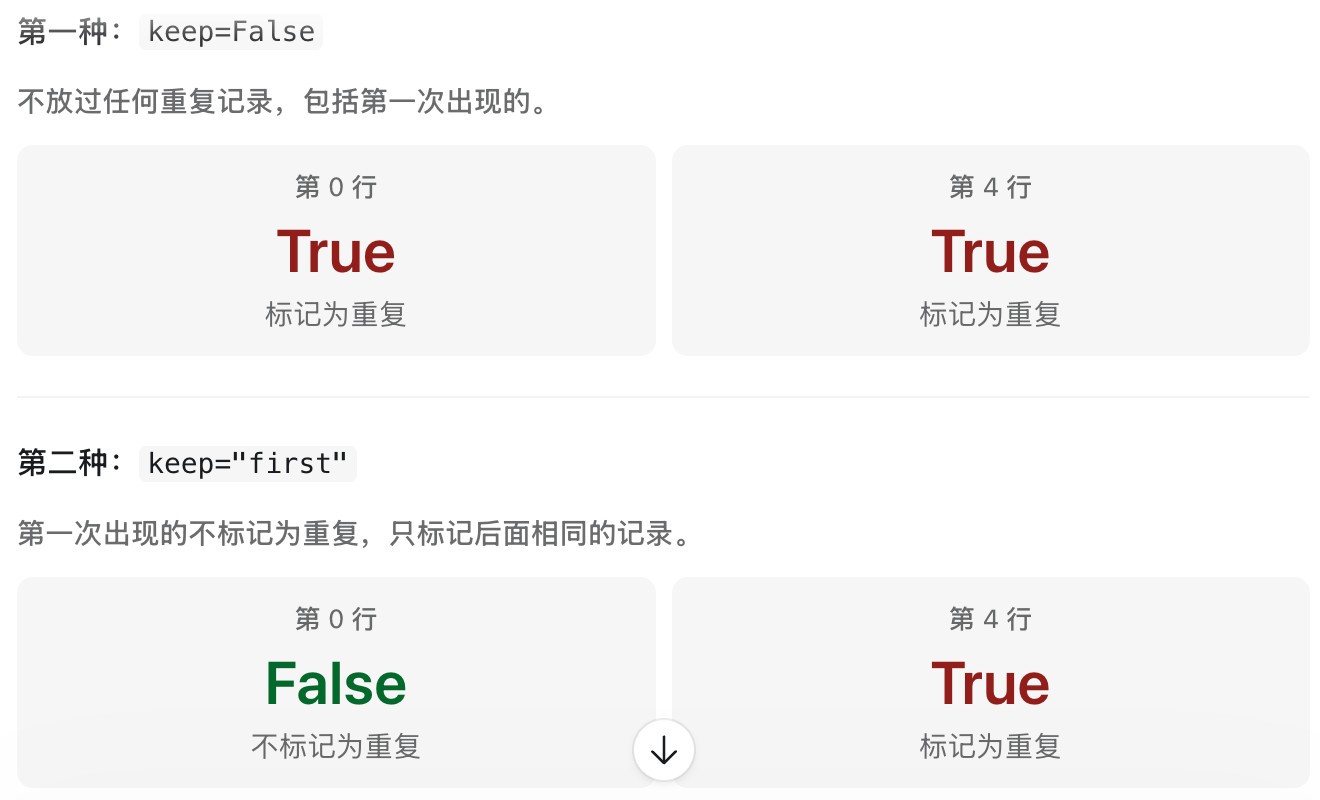

In [31]:
clean = raw.loc[~extra_copy]
display("extra_copy", extra_copy, "not extra_copy", ~extra_copy)
display("clean", clean)

paid_orders = clean.loc[clean["paid"]]
missing_paid = paid_orders["amount"].isna()
print("====================")
display("paid_orders", paid_orders)
display("missing_paid", missing_paid)
    
known_paid_amount = paid_orders["amount"].sum()
print(len(raw), len(clean), len(paid_orders))
print(missing_paid.sum(), known_paid_amount)
print("订单支付率:", len(paid_orders) / len(clean))

'extra_copy'

0    False
1    False
2    False
3    False
4     True
5    False
dtype: bool

'not extra_copy'

0     True
1     True
2     True
3     True
4    False
5     True
dtype: bool

'clean'

,order_id,user_id,amount,paid
0,O101,U01,100.0,True
1,O102,U01,NaN,True
2,O103,U02,80.0,True
3,O104,U03,60.0,False
5,O205,U04,500.0,True


'paid_orders'

,order_id,user_id,amount,paid
0,O101,U01,100.0,True
1,O102,U01,NaN,True
2,O103,U02,80.0,True
5,O205,U04,500.0,True


'missing_paid'

0    False
1     True
2    False
5    False
Name: amount, dtype: bool

6 5 4
1 680.0
订单支付率: 0.8
